### **Task 2 – Comparing diversity combining schemes**

**Plot the average BER of BPSK in a Rayleigh fading channel using a 3-branch maximal ratio combining (MRC) receiver**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from math import comb
from matplotlib.lines import Line2D

def qfunc(x):
    return 0.5 * erfc(x / np.sqrt(2))

EbN0_dB = np.arange(-10, 11, 1)
EbN0 = 10 ** (EbN0_dB / 10)
N = 10 ** 7

rng = np.random.default_rng(2)
L = 3

In [5]:
# MRC Simulation
ber_mrc_sim = np.zeros(len(EbN0_dB))

idx = np.arange(N)

for i, g in enumerate(EbN0):
    bits = rng.integers(0, 2, N)
    s = 2 * bits - 1
    N0 = 1 / g
    h = (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N))) / np.sqrt(2)
    n = np.sqrt(N0 / 2) * (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N)))
    r = h * s + n

    # MRC
    y_mrc = np.sum(np.conj(h) * r, axis=0)
    ber_mrc_sim[i] = np.mean((np.real(y_mrc) > 0).astype(int) != bits)

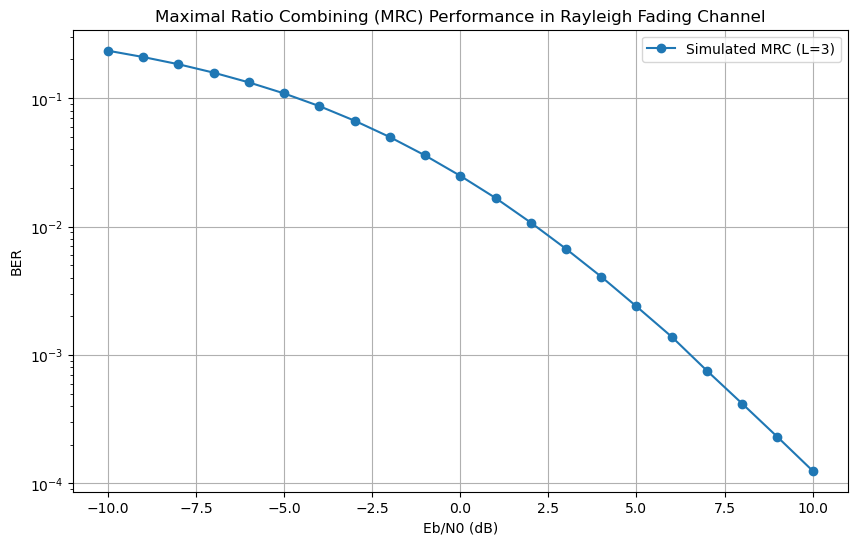

In [12]:
# Plotting the MRC Simulation Results
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_mrc_sim, 'o-', label='Simulated MRC (L=3)')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')
plt.title('Maximal Ratio Combining (MRC) Performance in Rayleigh Fading Channel')
plt.legend()
plt.grid(True)
plt.show()

**Theoretical BER for 3-branch Maximum Ratio Combining (MRC)**

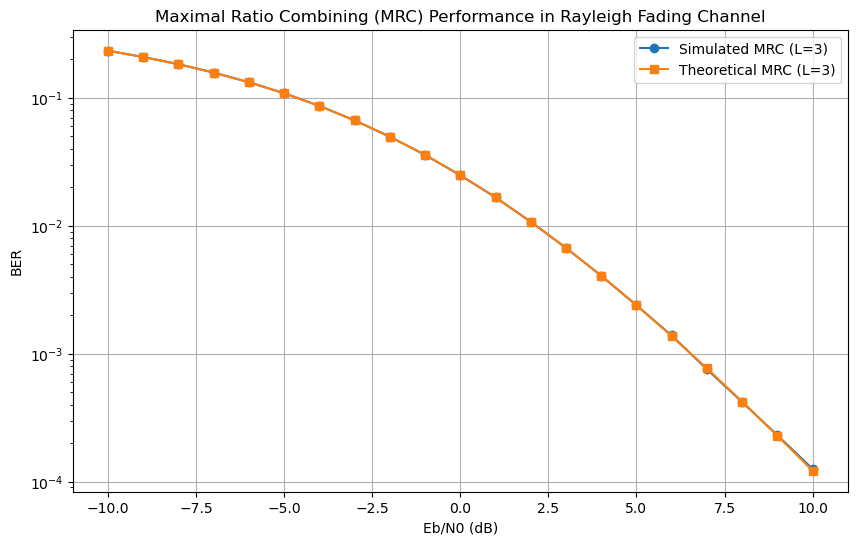

In [8]:
mu = np.sqrt(EbN0 / (1 + EbN0))
ber_mrc_th = ((1 - mu) / 2) ** L * sum(comb(L - 1 + l, l) * ((1 + mu) / 2) ** l for l in range(L))

# Plotting the Theoretical and Simulated BER for MRC
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_mrc_sim, 'o-', label='Simulated MRC (L=3)')
plt.semilogy(EbN0_dB, ber_mrc_th, 's-', label='Theoretical MRC (L=3)')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')
plt.title('Maximal Ratio Combining (MRC) Performance in Rayleigh Fading Channel')
plt.legend()
plt.grid(True)
plt.show()

**Plot the average BER of BPSK in a Rayleigh fading channel using a 3-branch Selection Combining (SC) receiver**

In [ ]:
# Selection Combining (SC) Simulation
ber_sc_sim = np.zeros(len(EbN0_dB))

for i, g in enumerate(EbN0):
    bits = rng.integers(0, 2, N)
    s = 2 * bits - 1
    N0 = 1 / g
    h = (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N))) / np.sqrt(2)
    n = np.sqrt(N0 / 2) * (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N)))
    r = h * s + n

    # Selection combining
    k = np.argmax(np.abs(h) ** 2, axis=0)
    y_sc = np.conj(h[k, idx]) * r[k, idx]
    ber_sc_sim[i] = np.mean((np.real(y_sc) > 0).astype(int) != bits)

In [16]:
# Theoretical BER for Selection Combining (SC)
ber_sc_th = sum((-1) ** (k + 1) * comb(L, k) * 0.5 * (1 - np.sqrt(EbN0 / (k + EbN0)))
                for k in range(1, L + 1))

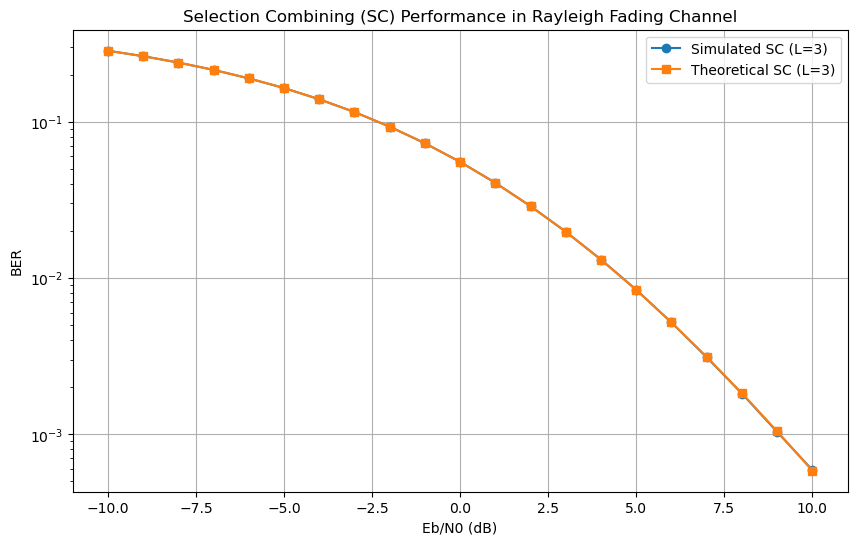

In [17]:
# Plotting the results for both simulated and theoretical BER for SC
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_sc_sim, 'o-', label='Simulated SC (L=3)')
plt.semilogy(EbN0_dB, ber_sc_th, 's-', label='Theoretical SC (L=3)')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')   
plt.title('Selection Combining (SC) Performance in Rayleigh Fading Channel')
plt.legend()
plt.grid(True)
plt.show()

**Plot Task 01 and Task 02 in same plot**

In [19]:
ber_ray_sim = np.zeros(len(EbN0))
ber_awgn_sim = np.zeros(len(EbN0))
idx = np.arange(N)

for i, g in enumerate(EbN0):
    bits = rng.integers(0, 2, N)
    s = 2 * bits - 1
    N0 = 1 / g
    h = (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N))) / np.sqrt(2)
    n = np.sqrt(N0 / 2) * (rng.standard_normal((L, N)) + 1j * rng.standard_normal((L, N)))
    r = h * s + n

    # Single branch (Task 1) and AWGN, reusing branch 0
    ber_ray_sim[i] = np.mean((np.real(np.conj(h[0]) * r[0]) > 0).astype(int) != bits)
    ber_awgn_sim[i] = np.mean((np.real(s + n[0]) > 0).astype(int) != bits)

ber_ray_th = 0.5 * (1 - mu)
ber_awgn_th = qfunc(np.sqrt(2 * EbN0))

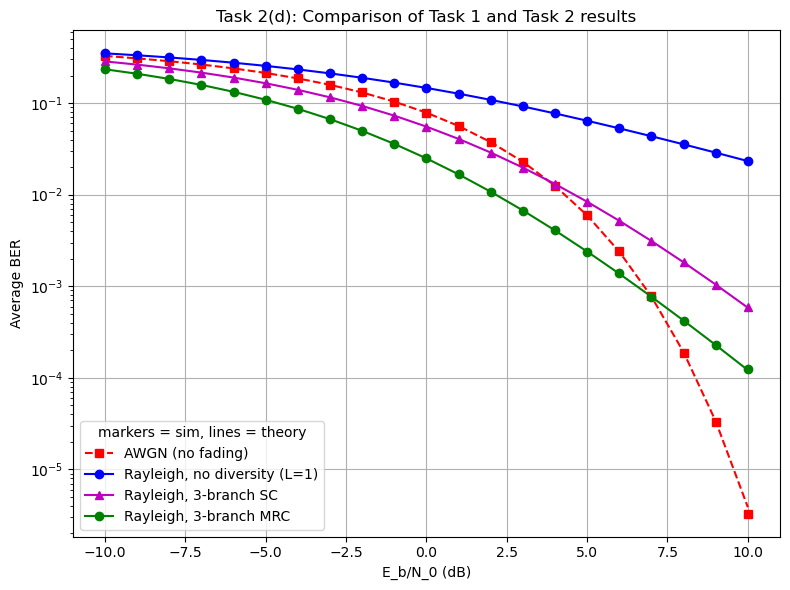

In [25]:
plt.figure(figsize=(8, 6))
plt.semilogy(EbN0_dB, ber_awgn_sim, 'rs', EbN0_dB, ber_awgn_th, 'r--')
plt.semilogy(EbN0_dB, ber_ray_sim, 'bo', EbN0_dB, ber_ray_th, 'b-')
plt.semilogy(EbN0_dB, ber_sc_sim, 'm^', EbN0_dB, ber_sc_th, 'm-')
plt.semilogy(EbN0_dB, ber_mrc_sim, 'go', EbN0_dB, ber_mrc_th, 'g-')
handles = [Line2D([], [], color='r', ls='--', marker='s', label='AWGN (no fading)'),
           Line2D([], [], color='b', marker='o', label='Rayleigh, no diversity (L=1)'),
           Line2D([], [], color='m', marker='^', label='Rayleigh, 3-branch SC'),
           Line2D([], [], color='g', marker='o', label='Rayleigh, 3-branch MRC')]
plt.legend(handles=handles, title='markers = sim, lines = theory')
plt.grid(True)
plt.xlabel('E_b/N_0 (dB)')
plt.ylabel('Average BER')
plt.title('Task 2(d): Comparison of Task 1 and Task 2 results'); plt.tight_layout()
plt.savefig('task2_all.png', dpi=150); plt.show()